In [1]:
import gc
import json
import sys

from pathlib import Path
from typing import Callable, List

import matplotlib.pyplot as plt
import numpy as np
import torch

from matplotlib.lines import Line2D
from peft import PeftConfig, PeftModel
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize as sk_normalize
from tqdm.auto import tqdm
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
)


# ============================================================================
# Project root
#
# Works when launched from:
#   - repository root
#   - notebooks/visualization/
#   - JupyterLab with another repository subdirectory as cwd
# ============================================================================

PROJECT_ROOT = Path.cwd().resolve()

while not (PROJECT_ROOT / "datasets").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError(
            "Could not locate repository root. "
            "Expected to find a 'datasets/' directory."
        )

    PROJECT_ROOT = PROJECT_ROOT.parent


if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )


from sparqlce.embedder import SPARQLEmbedder


print(f"Project root: {PROJECT_ROOT}")

/upb/users/g/ganeshk/profiles/unix/cs/.conda/envs/sparql/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings


In [2]:
# ============================================================================
# CONFIG
# ============================================================================

DATA_PATH = (
    PROJECT_ROOT
    / "datasets"
    / "dbpedia-triplets-dataset.json"
)


SPARQLCE_CHECKPOINT = (
    PROJECT_ROOT
    / "sparqlce"
    / "models"
    / "final_model_mrr_0.4487.pt"
)


# Fine-tuned Qwen model output.
#
# Keep this only if this is where your finetuning notebook saves the adapter.
QWEN_LORA_PATH = (
    PROJECT_ROOT
    / "results"
    / "finetuning"
    / "qwen_2.5_dbpedia"
)


OUTPUT_ROOT = (
    PROJECT_ROOT
    / "results"
    / "visualization"
    / "dbpedia"
)


QWEN_EMBED_MODEL_NAME = (
    "Qwen/Qwen3-Embedding-0.6B"
)

MINILM_MODEL_NAME = (
    "sentence-transformers/all-MiniLM-L6-v2"
)

E5_MODEL_NAME = (
    "intfloat/e5-base-v2"
)

MPNET_MODEL_NAME = (
    "sentence-transformers/all-mpnet-base-v2"
)


NUM_ANCHORS = 1

# "top_positive_count" or "random"
ANCHOR_SELECTION = "random"

# 0 = use complete corpus
SAMPLE_SIZE = 0


BATCH_SIZE = 32

QWEN_FT_BATCH_SIZE = 8
QWEN_FT_MAX_LENGTH = 768

TFIDF_MAX_FEATURES = 5000

SVD_DIM = 50

SEED = 10

DPI = 300


print(f"Dataset:             {DATA_PATH}")
print(f"SparqlCE checkpoint: {SPARQLCE_CHECKPOINT}")
print(f"Output directory:    {OUTPUT_ROOT}")

Dataset:             /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/datasets/dbpedia-triplets-dataset.json
SparqlCE checkpoint: /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/sparqlce/models/final_model_mrr_0.4487.pt
Output directory:    /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/visualization/dbpedia


In [3]:
# ============================================================================
# DATA HELPERS
# ============================================================================

def load_triplets(path: Path) -> List[dict]:
    """
    Load the triplet dataset.
    """
    with path.open(
        "r",
        encoding="utf-8",
    ) as f:
        return json.load(f)


def get_query_text(x) -> str:
    """
    Extract query text from either a string or a query dictionary.
    """
    if x is None:
        return ""

    if isinstance(x, dict):
        return str(
            x.get("query")
            or x.get("sparql")
            or ""
        ).strip()

    return str(x).strip()


def build_global_corpus(
    raw_data: List[dict],
) -> List[str]:
    """
    Build a deduplicated corpus containing anchors,
    positives, and negatives.
    """
    corpus = []
    seen = set()

    for item in raw_data:

        candidates = [
            item.get("anchor_query")
            or item.get("base_query")
        ]

        candidates.extend(
            item.get("positive_queries", [])
            or []
        )

        candidates.extend(
            item.get("negative_queries", [])
            or []
        )


        for candidate in candidates:

            query = get_query_text(
                candidate
            )

            if query and query not in seen:
                seen.add(query)
                corpus.append(query)


    return corpus

In [4]:
# ============================================================================
# GENERAL HELPERS
# ============================================================================

def set_seed(seed: int) -> None:
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def format_sparql_to_text_prompt(
    sparql: str,
) -> str:

    return (
        "You are an expert in knowledge graphs.\n\n"
        "### Instruction\n"
        "Convert the SPARQL query into a clear natural language question.\n\n"
        f"### SPARQL Query\n{sparql}\n\n"
        "### Natural Text\n"
    )


def l2_normalize(
    x: torch.Tensor,
    eps: float = 1e-12,
) -> torch.Tensor:

    return (
        x
        / x.norm(
            dim=-1,
            keepdim=True,
        ).clamp(min=eps)
    )


def sample_corpus(
    corpus: List[str],
    sample_size: int,
    seed: int,
) -> List[str]:

    if (
        sample_size <= 0
        or sample_size >= len(corpus)
    ):
        return corpus


    rng = np.random.default_rng(seed)

    selected = sorted(
        rng.choice(
            len(corpus),
            size=sample_size,
            replace=False,
        ).tolist()
    )


    return [
        corpus[i]
        for i in selected
    ]


def select_anchor_groups(
    raw_data: List[dict],
    num_anchors: int,
    mode: str,
    seed: int,
) -> List[dict]:

    filtered = [
        item
        for item in raw_data
        if get_query_text(
            item.get("anchor_query")
            or item.get("base_query")
        )
    ]


    if not filtered:
        return []


    if mode == "top_positive_count":

        filtered = sorted(
            filtered,
            key=lambda x: len(
                x.get(
                    "positive_queries",
                    [],
                )
                or []
            ),
            reverse=True,
        )

        return filtered[
            : min(
                num_anchors,
                len(filtered),
            )
        ]


    rng = np.random.default_rng(seed)

    idx = rng.choice(
        len(filtered),
        size=min(
            num_anchors,
            len(filtered),
        ),
        replace=False,
    )


    return [
        filtered[i]
        for i in sorted(
            idx.tolist()
        )
    ]


def ensure_anchor_items_in_corpus(
    corpus: List[str],
    anchor_items: List[dict],
) -> List[str]:

    seen = set(corpus)

    out = list(corpus)


    for item in anchor_items:

        candidates = [
            item.get("anchor_query")
            or item.get("base_query")
        ]

        candidates.extend(
            item.get("positive_queries", [])
            or []
        )

        candidates.extend(
            item.get("negative_queries", [])
            or []
        )


        for candidate in candidates:

            query = get_query_text(
                candidate
            )

            if query and query not in seen:
                out.append(query)
                seen.add(query)


    return out

In [5]:
# ============================================================================
# EMBEDDING BUILDERS
# ============================================================================

def build_tfidf_embeddings(
    corpus: List[str],
    max_features: int,
) -> np.ndarray:

    vectorizer = TfidfVectorizer(
        max_features=max_features,
    )

    X = vectorizer.fit_transform(
        corpus
    )

    X = sk_normalize(
        X,
        norm="l2",
        axis=1,
    )

    return (
        X
        .toarray()
        .astype(np.float32)
    )


def build_sentence_embeddings(
    corpus: List[str],
    model_name: str,
    batch_size: int,
    transform=None,
) -> np.ndarray:

    device = (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )


    model = SentenceTransformer(
        model_name,
        device=device,
    )


    texts = (
        [
            transform(query)
            for query in corpus
        ]
        if transform is not None
        else corpus
    )


    embeddings = model.encode(
        texts,
        batch_size=batch_size,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=True,
    )


    del model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    return embeddings.astype(
        np.float32
    )


def build_sparqlce_embeddings(
    corpus: List[str],
    checkpoint_path: Path,
    batch_size: int,
) -> np.ndarray:

    model = SPARQLEmbedder(
        str(checkpoint_path)
    )


    batches = []


    for start in tqdm(
        range(
            0,
            len(corpus),
            batch_size,
        ),
        desc="Encoding SparqlCE",
    ):

        batch = corpus[
            start : start + batch_size
        ]

        batch_embeddings = model.encode(
            batch
        )

        batches.append(
            np.asarray(
                batch_embeddings,
                dtype=np.float32,
            )
        )


    embeddings = np.vstack(
        batches
    )


    embeddings = sk_normalize(
        embeddings,
        norm="l2",
        axis=1,
    ).astype(np.float32)


    del model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    return embeddings

In [6]:
# ============================================================================
# FINE-TUNED QWEN LoRA ENCODER
# ============================================================================

class QwenSPARQLEncoder:

    def __init__(
        self,
        lora_path: str,
        device: str | None = None,
    ):

        self.device = (
            device
            or (
                "cuda"
                if torch.cuda.is_available()
                else "cpu"
            )
        )


        peft_cfg = PeftConfig.from_pretrained(
            lora_path
        )


        self.base_model_name = (
            peft_cfg.base_model_name_or_path
        )


        try:

            self.tokenizer = (
                AutoTokenizer
                .from_pretrained(
                    lora_path
                )
            )

        except Exception:

            self.tokenizer = (
                AutoTokenizer
                .from_pretrained(
                    self.base_model_name
                )
            )


        if self.tokenizer.pad_token is None:
            self.tokenizer.pad_token = (
                self.tokenizer.eos_token
            )


        if self.device == "cuda":

            bnb_config = BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_use_double_quant=True,
                bnb_4bit_quant_type="nf4",
                bnb_4bit_compute_dtype=torch.float16,
            )


            try:

                base_model = (
                    AutoModelForCausalLM
                    .from_pretrained(
                        self.base_model_name,
                        quantization_config=bnb_config,
                        device_map={
                            "":
                            torch.cuda.current_device()
                        },
                    )
                )


            except torch.cuda.OutOfMemoryError:

                base_model = (
                    AutoModelForCausalLM
                    .from_pretrained(
                        self.base_model_name,
                        quantization_config=bnb_config,
                        device_map="auto",
                        llm_int8_enable_fp32_cpu_offload=True,
                    )
                )


        else:

            base_model = (
                AutoModelForCausalLM
                .from_pretrained(
                    self.base_model_name,
                    torch_dtype=torch.float32,
                )
                .to(self.device)
            )


        self.model = PeftModel.from_pretrained(
            base_model,
            lora_path,
            is_trainable=False,
        )

        self.model.eval()


    @torch.no_grad()
    def encode_sparql(
        self,
        sparql_list: List[str],
        batch_size: int = 8,
        max_length: int = 768,
    ) -> np.ndarray:

        all_embeddings = []

        model_device = next(
            self.model.parameters()
        ).device


        for start in tqdm(
            range(
                0,
                len(sparql_list),
                batch_size,
            ),
            desc="Encoding Qwen LoRA",
        ):

            batch = sparql_list[
                start : start + batch_size
            ]


            prompts = [
                format_sparql_to_text_prompt(query)
                for query in batch
            ]


            tokens = self.tokenizer(
                prompts,
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=max_length,
            )


            tokens = {
                key: value.to(model_device)
                for key, value
                in tokens.items()
            }


            outputs = self.model(
                **tokens,
                output_hidden_states=True,
                return_dict=True,
            )


            last_hidden = (
                outputs.hidden_states[-1]
            )


            attention = (
                tokens["attention_mask"]
                .unsqueeze(-1)
                .float()
            )


            pooled = (
                (last_hidden * attention)
                .sum(dim=1)
                /
                attention
                .sum(dim=1)
                .clamp(min=1e-9)
            )


            pooled = l2_normalize(
                pooled
            )


            all_embeddings.append(
                pooled.cpu()
            )


        return (
            torch.cat(
                all_embeddings,
                dim=0,
            )
            .numpy()
        )


def build_qwen_lora_embeddings(
    corpus: List[str],
    lora_path: Path,
    batch_size: int,
    max_length: int,
) -> np.ndarray:

    model = QwenSPARQLEncoder(
        str(lora_path)
    )


    embeddings = model.encode_sparql(
        corpus,
        batch_size=batch_size,
        max_length=max_length,
    ).astype(np.float32)


    del model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    return embeddings

In [7]:
# ============================================================================
# DIMENSIONALITY REDUCTION
# ============================================================================

def reduce_to_2d(
    embeddings: np.ndarray,
    svd_dim: int,
    seed: int,
) -> np.ndarray:

    if embeddings.shape[0] < 3:
        raise ValueError(
            "Need at least 3 points to run t-SNE."
        )


    if embeddings.shape[1] > 50:

        n_components = min(
            svd_dim,
            embeddings.shape[1] - 1,
            embeddings.shape[0] - 1,
        )


        reducer = TruncatedSVD(
            n_components=max(
                2,
                n_components,
            ),
            random_state=seed,
        )


        reduced = reducer.fit_transform(
            embeddings
        )


    else:

        reduced = embeddings


    perplexity = min(
        30,
        max(
            5,
            embeddings.shape[0] // 3,
        ),
    )


    perplexity = min(
        perplexity,
        embeddings.shape[0] - 1,
    )


    tsne = TSNE(
        n_components=2,
        random_state=seed,
        perplexity=perplexity,
        init="pca",
        learning_rate="auto",
    )


    return tsne.fit_transform(
        reduced
    )

In [8]:
# ============================================================================
# LOAD DATASET
# ============================================================================

set_seed(SEED)


if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Triplet dataset not found:\n{DATA_PATH}"
    )


raw_data = load_triplets(
    DATA_PATH
)


global_corpus = build_global_corpus(
    raw_data
)


anchor_items = select_anchor_groups(
    raw_data=raw_data,
    num_anchors=NUM_ANCHORS,
    mode=ANCHOR_SELECTION,
    seed=SEED,
)


if not anchor_items:
    raise ValueError(
        "No valid anchor groups found in the dataset."
    )


corpus = sample_corpus(
    corpus=global_corpus,
    sample_size=SAMPLE_SIZE,
    seed=SEED,
)


corpus = ensure_anchor_items_in_corpus(
    corpus=corpus,
    anchor_items=anchor_items,
)


print(f"Loaded triplets:    {len(raw_data)}")
print(f"Global corpus:      {len(global_corpus)}")
print(f"Visualization corpus: {len(corpus)}")
print(f"Selected anchors:   {len(anchor_items)}")

Loaded triplets:    4713
Global corpus:      4727
Visualization corpus: 4727
Selected anchors:   1


In [9]:
# ============================================================================
# MODEL BUILDERS
# ============================================================================

model_builders: List[
    tuple[
        str,
        Callable[[], np.ndarray],
    ]
] = [


    (
        "TF-IDF",
        lambda: build_tfidf_embeddings(
            corpus,
            TFIDF_MAX_FEATURES,
        ),
    ),


    (
        "MiniLM",
        lambda: build_sentence_embeddings(
            corpus,
            MINILM_MODEL_NAME,
            BATCH_SIZE,
        ),
    ),


    (
        "MPNet",
        lambda: build_sentence_embeddings(
            corpus,
            MPNET_MODEL_NAME,
            BATCH_SIZE,
        ),
    ),


    (
        "E5-base-v2",
        lambda: build_sentence_embeddings(
            corpus,
            E5_MODEL_NAME,
            BATCH_SIZE,
            transform=lambda query: (
                f"query: {query}"
            ),
        ),
    ),


    (
        "Qwen3-Embedding-0.6B",
        lambda: build_sentence_embeddings(
            corpus,
            QWEN_EMBED_MODEL_NAME,
            BATCH_SIZE,
        ),
    ),

]


if SPARQLCE_CHECKPOINT.is_file():

    model_builders.append(
        (
            "SparqlCE",
            lambda: build_sparqlce_embeddings(
                corpus,
                SPARQLCE_CHECKPOINT,
                BATCH_SIZE,
            ),
        )
    )

else:

    print(
        "Skip SparqlCE: checkpoint not found at\n"
        f"{SPARQLCE_CHECKPOINT}"
    )


if QWEN_LORA_PATH.is_dir():

    model_builders.append(
        (
            "Fine-tuned Qwen2.5 LoRA",
            lambda: build_qwen_lora_embeddings(
                corpus,
                QWEN_LORA_PATH,
                QWEN_FT_BATCH_SIZE,
                QWEN_FT_MAX_LENGTH,
            ),
        )
    )

else:

    print(
        "Skip Fine-tuned Qwen2.5 LoRA: "
        "directory not found at\n"
        f"{QWEN_LORA_PATH}"
    )

Skip Fine-tuned Qwen2.5 LoRA: directory not found at
/upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/finetuning/qwen_2.5_dbpedia


In [10]:
# ============================================================================
# COMPUTE MODEL SPACES ONCE
# ============================================================================

model_spaces = {}


for model_name, builder in model_builders:

    print(
        f"\nBuilding embedding space for {model_name}..."
    )


    embeddings = builder()


    print(
        f"{model_name}: embeddings shape = "
        f"{embeddings.shape}"
    )


    x_2d = reduce_to_2d(
        embeddings=embeddings,
        svd_dim=SVD_DIM,
        seed=SEED,
    )


    model_spaces[model_name] = x_2d


    del embeddings

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


Building embedding space for TF-IDF...
TF-IDF: embeddings shape = (4727, 4357)

Building embedding space for MiniLM...


Batches: 100%|██████████| 148/148 [00:02<00:00, 71.94it/s] 


MiniLM: embeddings shape = (4727, 384)

Building embedding space for MPNet...


Batches: 100%|██████████| 148/148 [00:10<00:00, 14.34it/s]


MPNet: embeddings shape = (4727, 768)

Building embedding space for E5-base-v2...


...

Qwen3-Embedding-0.6B: embeddings shape = (4727, 1024)

Building embedding space for SparqlCE...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 26367.60it/s]


Loading model from /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/sparqlce/models/final_model_mrr_0.4487.pt...


Encoding SparqlCE: 100%|██████████| 148/148 [00:09<00:00, 15.03it/s]


SparqlCE: embeddings shape = (4727, 128)


In [11]:
# ============================================================================
# PLOTTING HELPERS
# ============================================================================

def sanitize_filename(name: str) -> str:
    """
    Convert a model name into a filesystem-safe filename stem.
    """
    return "".join(
        char.lower() if char.isalnum() else "_"
        for char in name
    ).strip("_")


def make_legend_handles():
    """
    Create legend entries for anchor, positive, and hard-negative queries.
    """
    return [
        Line2D(
            [0],
            [0],
            marker="*",
            color="w",
            markerfacecolor="blue",
            markeredgecolor="black",
            markersize=15,
            label="Anchor Query",
        ),
        Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            markerfacecolor="#2ca02c",
            markeredgecolor="black",
            markersize=9,
            label="True Positive",
        ),
        Line2D(
            [0],
            [0],
            marker="X",
            color="w",
            markerfacecolor="#d62728",
            markeredgecolor="black",
            markersize=9,
            label="Hard Negative",
        ),
    ]


def plot_failure_mode(
    x_2d: np.ndarray,
    corpus: List[str],
    anchor_items: List[dict],
    title: str,
    save_path: Path,
    dpi: int,
) -> None:
    """
    Plot a 2D embedding visualization highlighting:
      - anchor query
      - true positives
      - hard negatives
      - background corpus queries
    """

    corpus_to_idx = {
        text: idx
        for idx, text in enumerate(corpus)
    }


    colors = np.array(
        ["#E0E0E0"] * len(corpus),
        dtype=object,
    )

    sizes = np.array(
        [10] * len(corpus)
    )

    zorders = np.array(
        [1] * len(corpus)
    )

    markers = np.array(
        ["o"] * len(corpus),
        dtype=object,
    )


    for item in anchor_items:

        anchor = get_query_text(
            item.get("anchor_query")
            or item.get("base_query")
        )

        positives = (
            item.get("positive_queries", [])
            or []
        )

        negatives = (
            item.get("negative_queries", [])
            or []
        )


        # Anchor
        if anchor in corpus_to_idx:

            idx = corpus_to_idx[anchor]

            colors[idx] = "blue"
            sizes[idx] = 220
            zorders[idx] = 10
            markers[idx] = "*"


        # Positives
        for pos in positives:

            query = get_query_text(pos)

            if query in corpus_to_idx:

                idx = corpus_to_idx[query]

                colors[idx] = "#2ca02c"
                sizes[idx] = 75
                zorders[idx] = 8
                markers[idx] = "o"


        # Hard negatives
        for neg in negatives:

            query = get_query_text(neg)

            if query in corpus_to_idx:

                idx = corpus_to_idx[query]

                colors[idx] = "#d62728"
                sizes[idx] = 75
                zorders[idx] = 7
                markers[idx] = "X"


    plt.figure(
        figsize=(14, 9)
    )


    # Background corpus
    background_mask = (
        zorders == 1
    )

    plt.scatter(
        x_2d[background_mask, 0],
        x_2d[background_mask, 1],
        c=colors[background_mask],
        s=sizes[background_mask],
        alpha=0.5,
        zorder=1,
    )


    # Highlighted query groups
    for marker in [
        "o",
        "X",
        "*",
    ]:

        mask = (
            (markers == marker)
            & (zorders > 1)
        )

        if np.any(mask):

            plt.scatter(
                x_2d[mask, 0],
                x_2d[mask, 1],
                c=colors[mask],
                s=sizes[mask],
                marker=marker,
                alpha=0.9,
                zorder=5,
                edgecolors="black",
                linewidth=0.5,
            )


    plt.title(
        title,
        fontsize=15,
        pad=15,
    )

    plt.xlabel(
        "t-SNE Dimension 1",
        fontsize=12,
    )

    plt.ylabel(
        "t-SNE Dimension 2",
        fontsize=12,
    )

    plt.legend(
        handles=make_legend_handles(),
        loc="upper right",
        fontsize=11,
        framealpha=0.9,
    )

    plt.grid(
        True,
        linestyle="--",
        alpha=0.3,
    )

    plt.tight_layout()


    save_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )


    plt.savefig(
        save_path,
        dpi=dpi,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()


Anchor 1 directory: /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/visualization/dbpedia/dbpedia_anchor_1_s2_run_1
Saved anchor text to: /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/visualization/dbpedia/dbpedia_anchor_1_s2_run_1/selected_anchor.txt
Plotting TF-IDF for anchor 1...


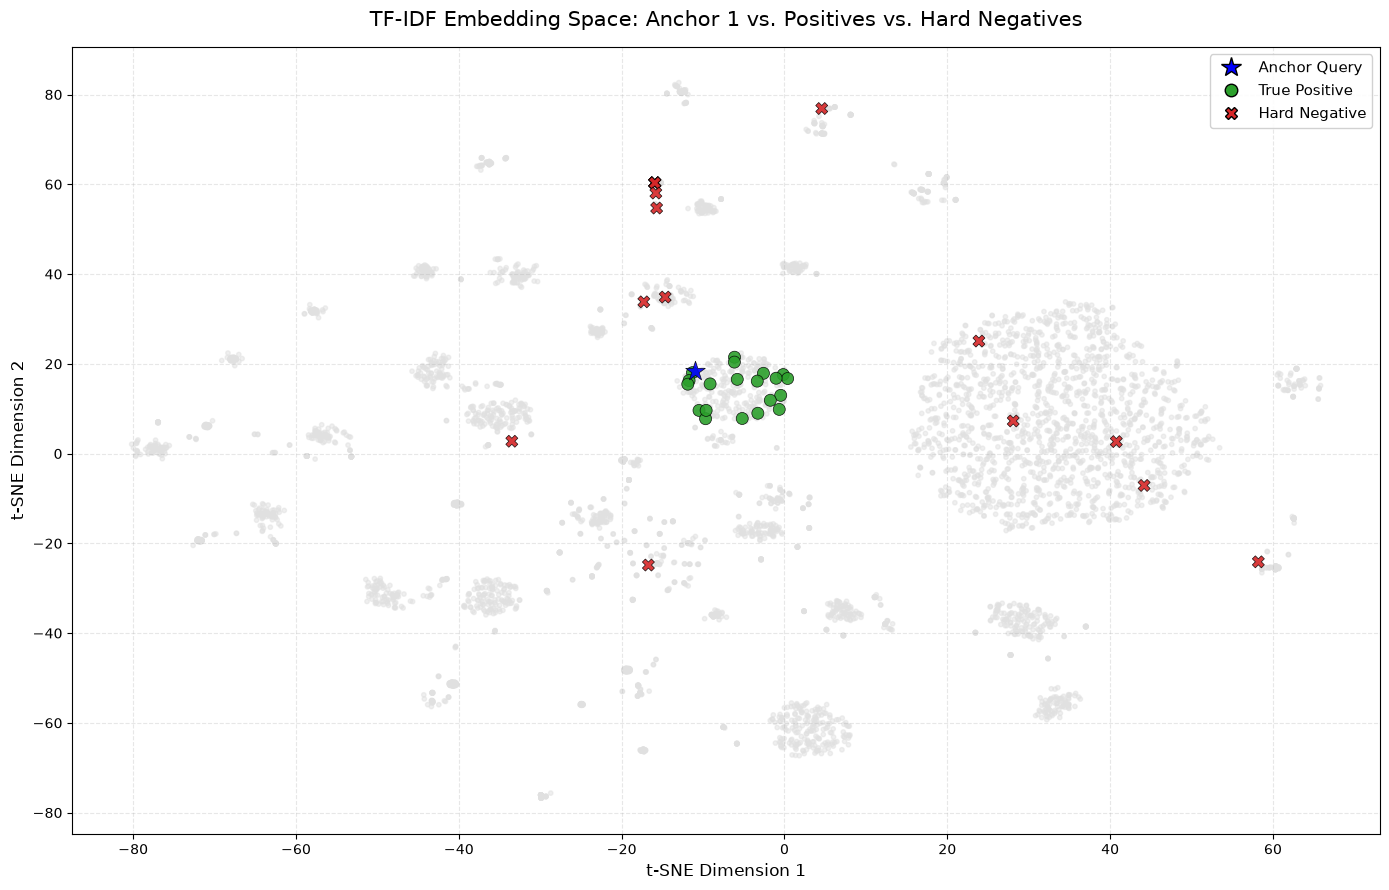

Saved /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/visualization/dbpedia/dbpedia_anchor_1_s2_run_1/tf_idf.png
Plotting MiniLM for anchor 1...


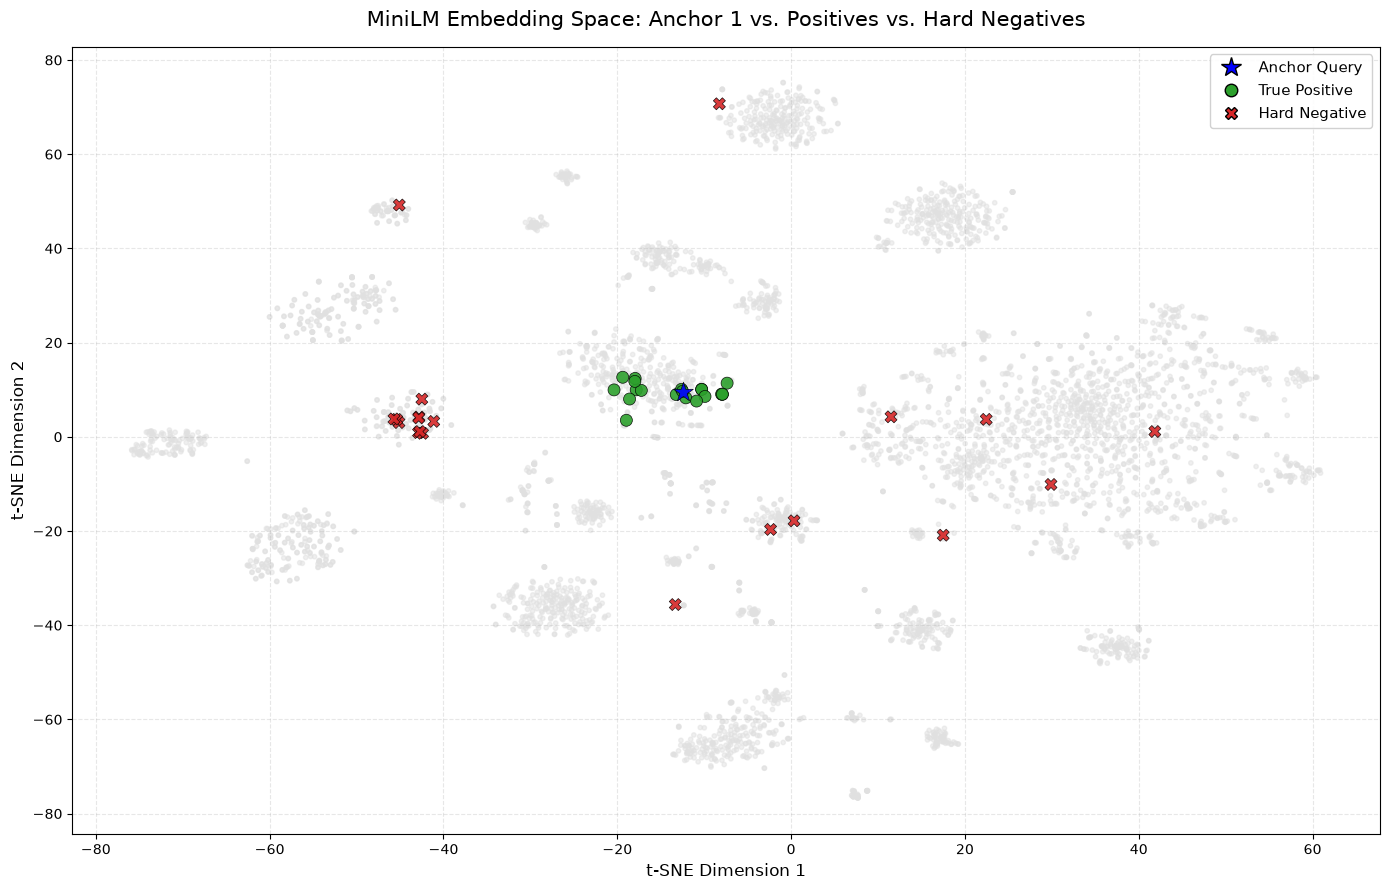

Saved /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/visualization/dbpedia/dbpedia_anchor_1_s2_run_1/minilm.png
Plotting MPNet for anchor 1...


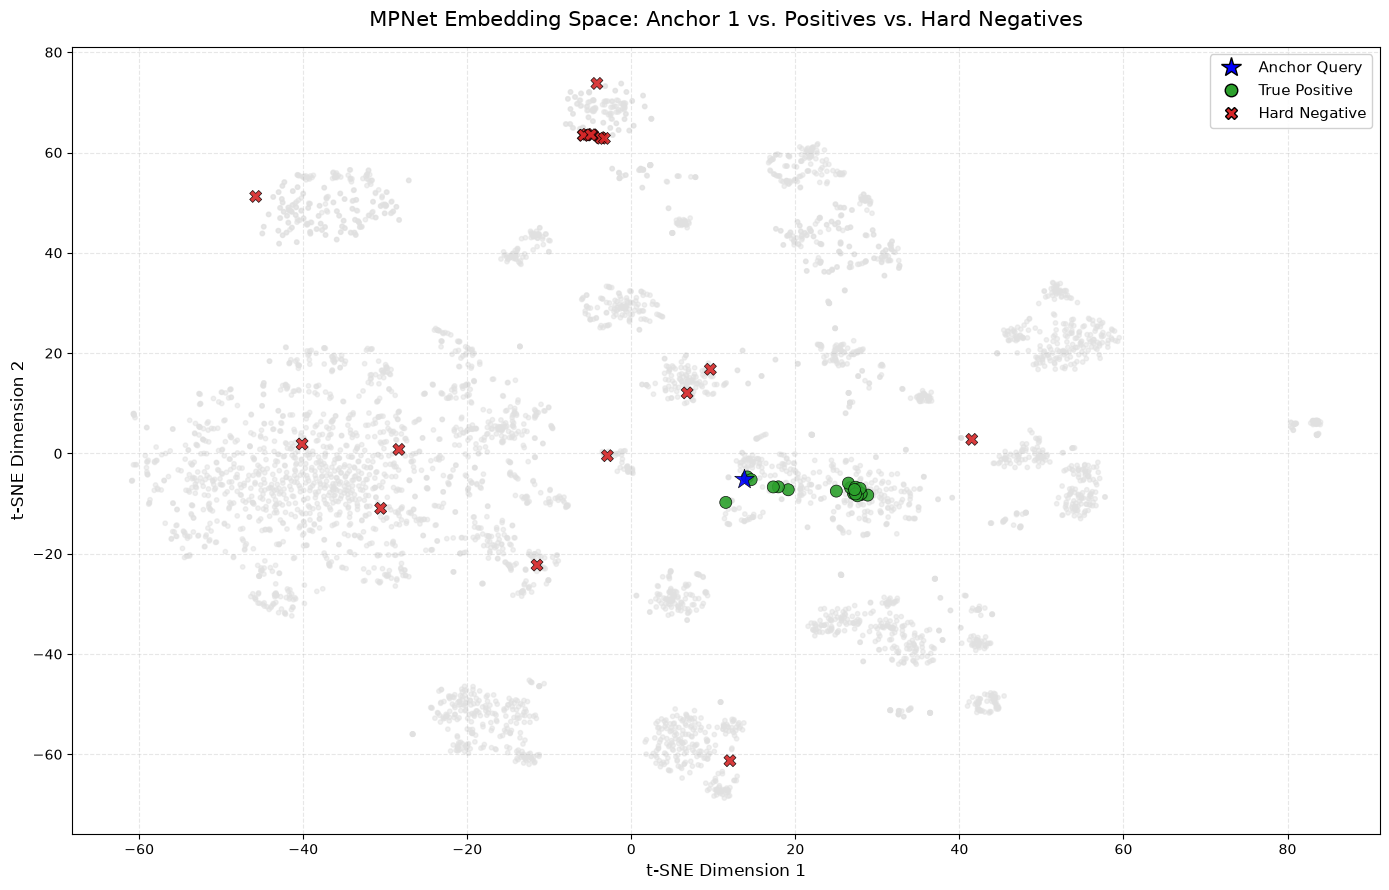

Saved /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/visualization/dbpedia/dbpedia_anchor_1_s2_run_1/mpnet.png
Plotting E5-base-v2 for anchor 1...


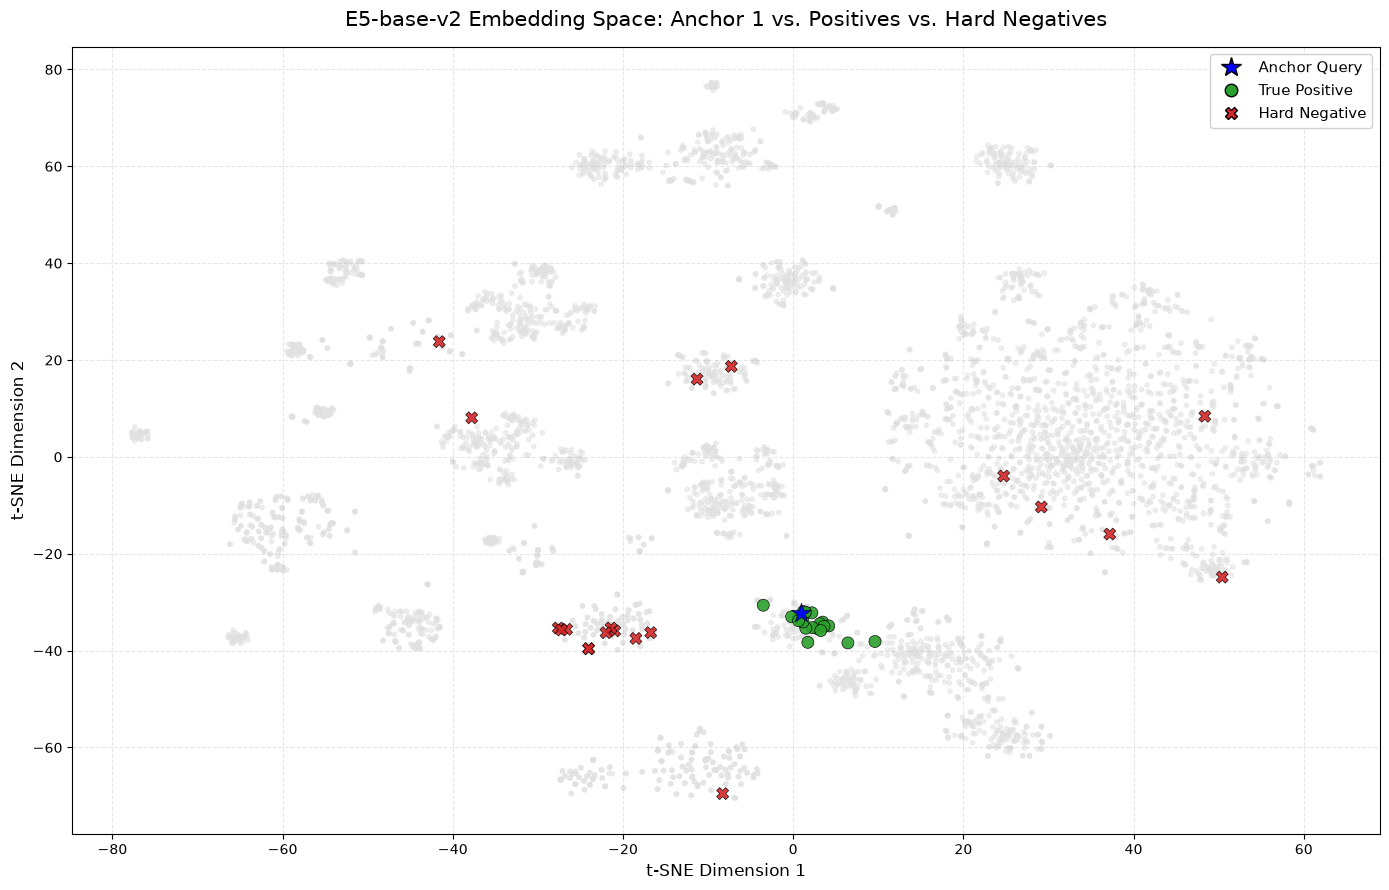

Saved /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/visualization/dbpedia/dbpedia_anchor_1_s2_run_1/e5_base_v2.png
Plotting Qwen3-Embedding-0.6B for anchor 1...


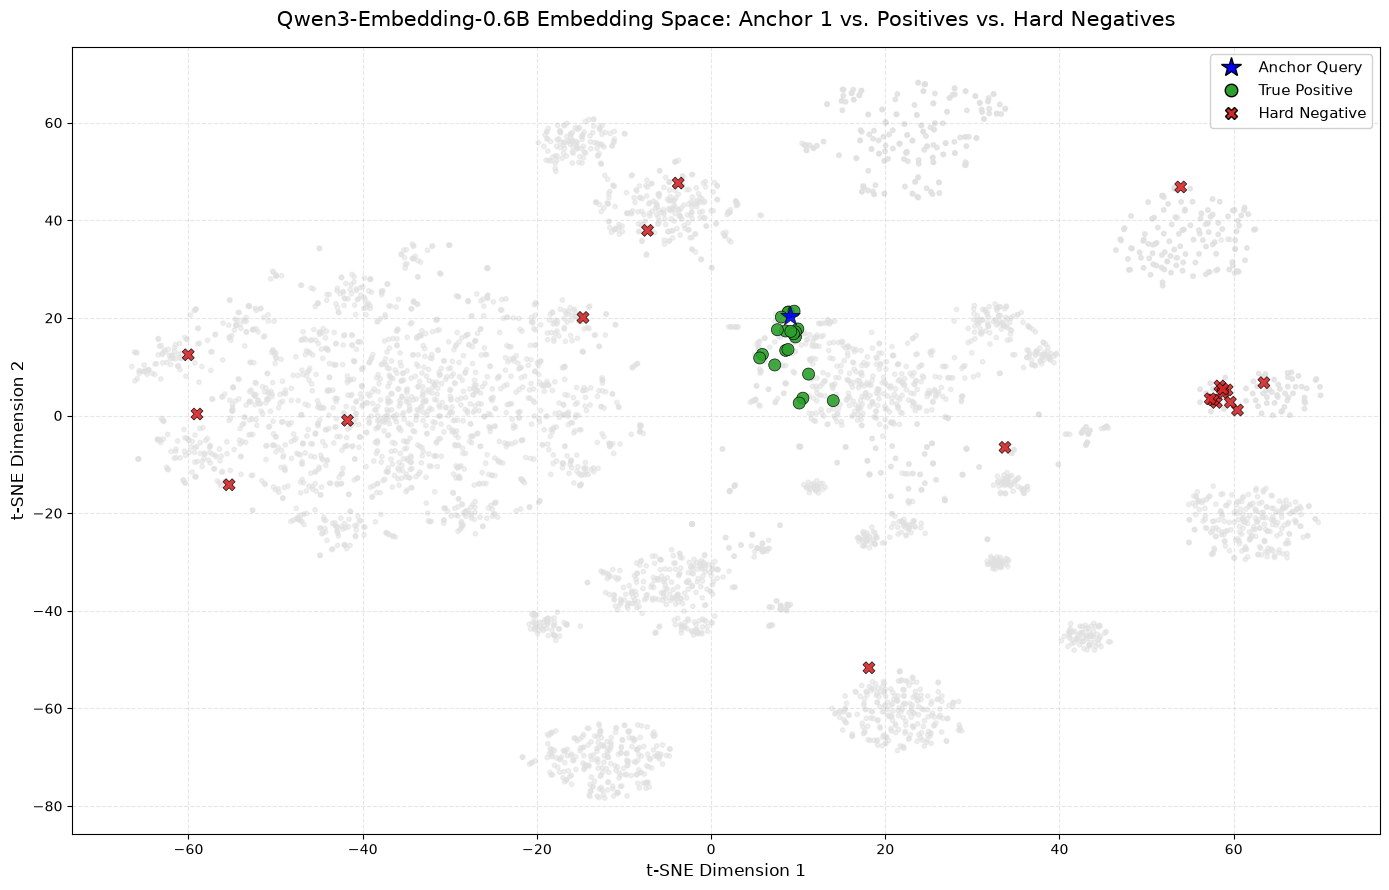

Saved /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/visualization/dbpedia/dbpedia_anchor_1_s2_run_1/qwen3_embedding_0_6b.png
Plotting SparqlCE for anchor 1...


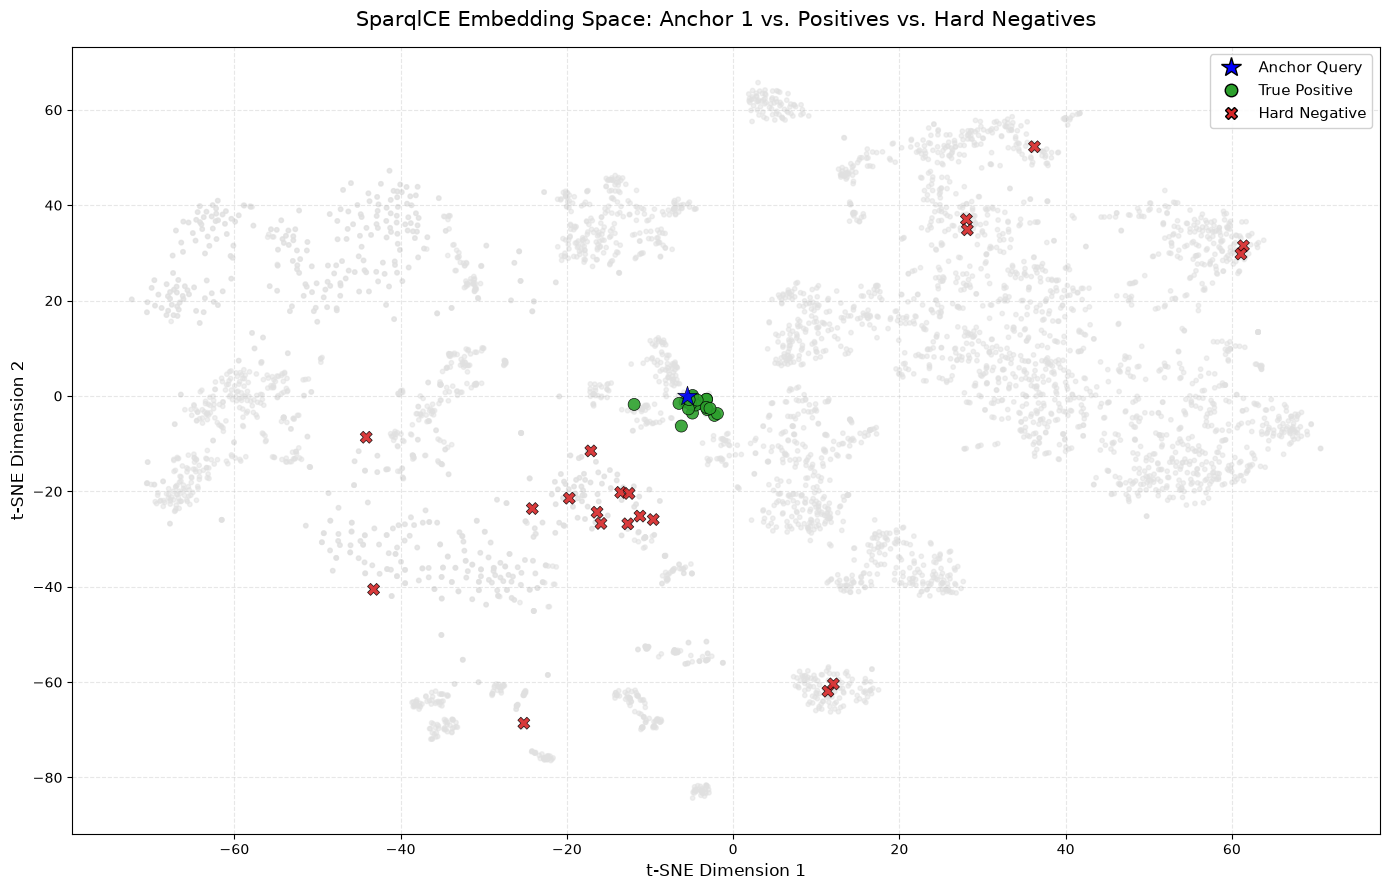

Saved /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/visualization/dbpedia/dbpedia_anchor_1_s2_run_1/sparqlce.png


In [12]:
# ============================================================================
# GENERATE VISUALIZATIONS
# ============================================================================

dataset_label = "dbpedia"


for anchor_idx, anchor_item in enumerate(
    anchor_items,
    start=1,
):


    anchor = get_query_text(
        anchor_item.get("anchor_query")
        or anchor_item.get("base_query")
    )


    base_name = (
        f"{dataset_label}"
        f"_anchor_{anchor_idx}"
        f"_s{SEED}"
    )


    run_num = 1


    run_dir = (
        OUTPUT_ROOT
        / f"{base_name}_run_{run_num}"
    )


    while run_dir.exists():

        run_num += 1

        run_dir = (
            OUTPUT_ROOT
            / f"{base_name}_run_{run_num}"
        )


    run_dir.mkdir(
        parents=True,
        exist_ok=False,
    )


    selected_anchor_file = (
        run_dir
        / "selected_anchor.txt"
    )


    with selected_anchor_file.open(
        "w",
        encoding="utf-8",
    ) as f:

        f.write(
            f"[Anchor {anchor_idx}]\n"
            f"{anchor}\n"
        )


    print(
        f"\nAnchor {anchor_idx} directory: "
        f"{run_dir}"
    )

    print(
        f"Saved anchor text to: "
        f"{selected_anchor_file}"
    )


    anchor_group = [
        anchor_item
    ]


    for model_name, x_2d in model_spaces.items():

        print(
            f"Plotting {model_name} "
            f"for anchor {anchor_idx}..."
        )


        save_path = (
            run_dir
            / f"{sanitize_filename(model_name)}.png"
        )


        title = (
            f"{model_name} Embedding Space: "
            f"Anchor {anchor_idx} vs. "
            f"Positives vs. Hard Negatives"
        )


        plot_failure_mode(
            x_2d=x_2d,
            corpus=corpus,
            anchor_items=anchor_group,
            title=title,
            save_path=save_path,
            dpi=DPI,
        )


        print(
            f"Saved {save_path}"
        )